# ResNet-50 DA

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import medmnist
import numpy as np
import os
import matplotlib.pyplot as plt
import sklearn.metrics as skmetrics
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision import models
from medmnist import INFO, Evaluator
from tqdm import tqdm
from sklearn.metrics import roc_curve, auc as metrics_auc, f1_score, accuracy_score, hamming_loss, balanced_accuracy_score, confusion_matrix

# Early Stopping Class
class EarlyStopping:
    def __init__(self, patience=3, verbose=False, delta=0, path='best_resnet50_standard_28x28.pth'):
        """
        Args:
            patience (int): epochs to wait after the last improvement.
            verbose (bool): if True, prints a message for each improvement.
            delta (float): Minimum change in the monitored metric to be considered as an improvement.
            path (str): Path where the best model will be saved.
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.auc_max = -np.inf
        self.delta = delta
        self.path = path

    def __call__(self, auc, model):
        score = auc

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(auc, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            print(f'EarlyStopping counter: {self.counter} out of {self.patience}\n')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(auc, model)
            self.counter = 0

    def save_checkpoint(self, auc, model):
        '''Saves the model when the AUC improves.'''
        if self.verbose:
            print(f'AUC improved ({self.auc_max:.4f} -> {auc:.4f}). Saving model.\n')
        torch.save(model.state_dict(), self.path)
        self.auc_max = auc

In [2]:
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_da_224x224.pth')

# Parameters
DATA_FLAG = 'chestmnist'
DOWNLOAD = True
BATCH_SIZE = 64
EPOCHS = 50
PATIENCE = 2
LEARNING_RATE = 1e-4
EARLY_STOPPING = EarlyStopping(patience=PATIENCE, verbose=True, path=MODEL_PATH)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

info = INFO[DATA_FLAG]
n_classes = len(info['label'])

# Data Transforms
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(degrees=15),  # Clave: + hasta 10.2% en AUC [citation:7]
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),  # Traslación [citation:7]
    transforms.RandomHorizontalFlip(p=0.5),  # Simetría anatómica
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
data_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

# Datasets and DataLoaders
train_dataset = medmnist.ChestMNIST(split='train', transform=train_transform, download=DOWNLOAD, size=224)
val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)

train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Torchvision ResNet-50 for multi-label task pretrained on ImageNet
if not os.path.exists(MODEL_DIR):
    os.makedirs(MODEL_DIR)
if os.path.exists(MODEL_PATH):
    print(f"Saved model detected. Loading weights from {MODEL_PATH}")
    model = models.resnet50(weights=None)
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, n_classes)
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
else:
    print("No saved model found. Starting with ImageNet weights.")
    model = models.resnet50(weights='IMAGENET1K_V1')
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, n_classes)
model = model.to(DEVICE)

# BCEWithLogitsLoss for multi-label classification (sigmoid + binary cross-entropy)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE)
evaluator = Evaluator(DATA_FLAG, split='val')

# Training and validation loop with early stopping
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for inputs, targets in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation phase
    model.eval()
    y_score = torch.tensor([]).to(DEVICE)
    val_loss = 0
    
    with torch.no_grad():
        for inputs, targets in tqdm(val_loader, desc=f"Epoch {epoch+1} [Val]"):
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
            outputs = model(inputs)
            
            val_loss += criterion(outputs, targets).item()
            
            # Probabilities for AUC
            m = nn.Sigmoid()
            y_score = torch.cat((y_score, m(outputs)), 0)

    # Calculate AUC and Accuracy
    auc, acc = evaluator.evaluate(y_score.cpu().numpy())
    
    print(f"Epoch {epoch+1}: Loss: {val_loss/len(val_loader):.4f} | AUC: {auc:.4f} | Acc: {acc:.4f}")

    # Early Stopping Check
    EARLY_STOPPING(auc, model)
    
    if EARLY_STOPPING.early_stop:
        print("\nEarly stopping activated. Terminating training.")
        break

Using device: cuda
No saved model found. Starting with ImageNet weights.


Epoch 1 [Val]: 100%|██████████| 176/176 [00:22<00:00,  7.83it/s]


Epoch 1: Loss: 0.1502 | AUC: 0.8109 | Acc: 0.9496
AUC improved (-inf -> 0.8109). Saving model.



Epoch 2 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.21it/s]


Epoch 2: Loss: 0.1498 | AUC: 0.8195 | Acc: 0.9491
AUC improved (0.8109 -> 0.8195). Saving model.



Epoch 3 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.21it/s]


... (11 outputs left out)

Epoch 9 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.20it/s]


Epoch 9: Loss: 0.1481 | AUC: 0.8370 | Acc: 0.9495
EarlyStopping counter: 1 out of 2



Epoch 10 [Val]: 100%|██████████| 176/176 [00:21<00:00,  8.18it/s]


Epoch 10: Loss: 0.1472 | AUC: 0.8397 | Acc: 0.9497
EarlyStopping counter: 2 out of 2


Early stopping activated. Terminating training.


Cargando los mejores pesos del modelo guardados por Early Stopping...
Saved model detected. Loading weights from models\best_resnet50_da_224x224.pth


Calibrando Umbrales (Val Set): 100%|██████████| 176/176 [00:22<00:00,  7.81it/s]



--- Umbrales Óptimos (optimizando F1 por clase) ---
atelectasis     -> 0.1602
cardiomegaly    -> 0.1602
effusion        -> 0.1602
infiltration    -> 0.1602
mass            -> 0.1602
nodule          -> 0.1602
pneumonia       -> 0.1602
pneumothorax    -> 0.1602
consolidation   -> 0.1602
edema           -> 0.1602
emphysema       -> 0.1602
fibrosis        -> 0.1602
pleural         -> 0.1602
hernia          -> 0.1602


Evaluación Final (Test Set): 100%|██████████| 351/351 [00:44<00:00,  7.96it/s]



   RESULTADOS FINALES EN TEST SET
- AUC-ROC Macro Media  : 0.8368
- Hamming Score (Acc)  : 0.9127
- Mean Balanced Acc    : 0.6564
- F1-Score Macro       : 0.3107
- F1-Score Micro       : 0.3868
- Accuracy Global (EMR): 0.3978


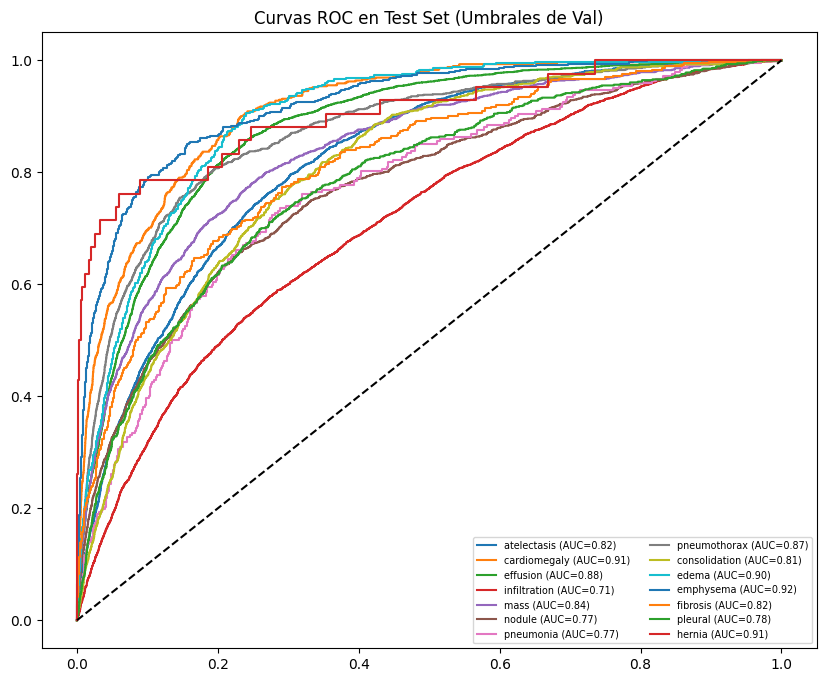

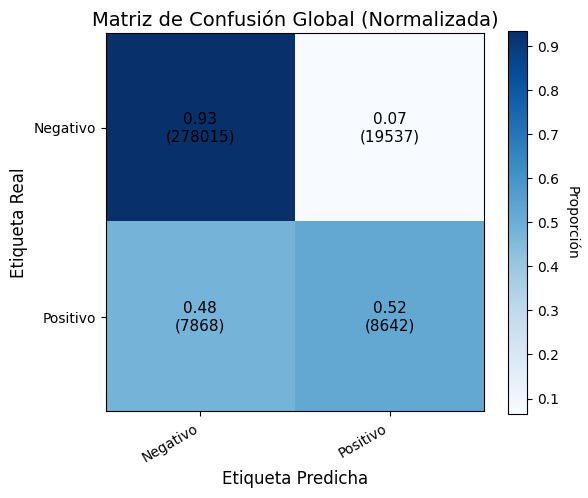

In [2]:
# Fase de calibración de umbrales usando el set de validación
# ===== VALIDATION: obtener scores =====
print("Cargando los mejores pesos del modelo guardados por Early Stopping...")
# VARIABLES NECESARIAS PARA LA CARGA
MODEL_DIR = 'models'
MODEL_PATH = os.path.join(MODEL_DIR, 'best_resnet50_da_224x224.pth')
DATA_FLAG = 'chestmnist'
info = INFO[DATA_FLAG]
n_classes = len(info['label'])
DOWNLOAD = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
criterion = nn.BCEWithLogitsLoss()
#######################################################################
print(f"Saved model detected. Loading weights from {MODEL_PATH}")
model = models.resnet50(weights=None)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, n_classes)
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model = model.to(DEVICE)
model.load_state_dict(torch.load(MODEL_PATH))

data_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3), # 3 channels for ResNet-50 (RGB)
    transforms.ToTensor(), # To tensor, normalization to [0,1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Normalization of ImageNet 
])

val_dataset = medmnist.ChestMNIST(split='val', transform=data_transform, download=DOWNLOAD, size=224)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model.to(DEVICE)
model.eval()

y_score_val = []
y_true_val = []

with torch.no_grad():
    for inputs, targets in tqdm(val_loader, desc="Calibrando Umbrales (Val Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = model(inputs)

        y_score_val.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_val.append(targets.cpu().numpy())

y_score_val = np.vstack(y_score_val)
y_true_val = np.vstack(y_true_val)

# ===== OPTIMIZACIÓN DE THRESHOLDS POR CLASE (F1) =====
num_classes = y_true_val.shape[1]
optimal_thresholds = np.zeros(num_classes)

best_f1 = 0
best_thresholds = None

for t in np.linspace(0.05, 0.5, 50):
    y_pred = (y_score_val >= t).astype(int)
    f1 = f1_score(y_true_val, y_pred, average='macro', zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        best_thresholds = np.full(num_classes, t)

optimal_thresholds = best_thresholds

# ===== PRINT =====
print("\n--- Umbrales Óptimos (optimizando F1 por clase) ---")
for i in range(num_classes):
    print(f"{info['label'][str(i)][:15]:<15} -> {optimal_thresholds[i]:.4f}")



# Fase de evaluación final en el set de test
# Cargar set de test
test_dataset = medmnist.ChestMNIST(split='test', transform=data_transform, download=DOWNLOAD, size=224)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

y_score_test = []
y_true_test = []
test_loss = 0

with torch.no_grad():
    for inputs, targets in tqdm(test_loader, desc="Evaluación Final (Test Set)"):
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE).float()
        outputs = model(inputs)
        test_loss += criterion(outputs, targets).item()
        y_score_test.append(torch.sigmoid(outputs).cpu().numpy())
        y_true_test.append(targets.cpu().numpy())

y_score_test = np.vstack(y_score_test)
y_true_test = np.vstack(y_true_test)

# Aplicar los umbrales de VALIDATION al TEST
y_pred_test = (y_score_test >= optimal_thresholds).astype(int)

# --- Cálculo de Métricas ---
from sklearn.metrics import auc as metrics_auc

roc_aucs_test = [metrics_auc(roc_curve(y_true_test[:, i], y_score_test[:, i])[0], 
                             roc_curve(y_true_test[:, i], y_score_test[:, i])[1]) for i in range(num_classes)]

acc_global = accuracy_score(y_true_test, y_pred_test)
f1_macro = f1_score(y_true_test, y_pred_test, average='macro', zero_division=0)
f1_micro = f1_score(y_true_test, y_pred_test, average='micro', zero_division=0)
h_score = 1 - hamming_loss(y_true_test, y_pred_test)

# Balanced Accuracy Promedio
balanced_accs = [balanced_accuracy_score(y_true_test[:, i], y_pred_test[:, i]) for i in range(num_classes)]

# Imprimir Resultados Finales
print(f"\n{'='*40}")
print(f"   RESULTADOS FINALES EN TEST SET")
print(f"{'='*40}")
print(f"- AUC-ROC Macro Media  : {np.mean(roc_aucs_test):.4f}")
print(f"- Hamming Score (Acc)  : {h_score:.4f}")
print(f"- Mean Balanced Acc    : {np.mean(balanced_accs):.4f}")
print(f"- F1-Score Macro       : {f1_macro:.4f}")
print(f"- F1-Score Micro       : {f1_micro:.4f}")
print(f"- Accuracy Global (EMR): {acc_global:.4f}")
print(f"{'='*40}")

# Graficar las curvas ROC del TEST
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_test[:, i], y_score_test[:, i])
    plt.plot(fpr, tpr, label=f"{info['label'][str(i)]} (AUC={roc_aucs_test[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Curvas ROC en Test Set (Umbrales de Val)')
plt.legend(loc='lower right', ncol=2, fontsize='x-small')
plt.show()



# Matriz de confusión global
cm_global = confusion_matrix(y_true_test.flatten(), y_pred_test.flatten())

# Normalización (opcional, recomendado)
cm_norm = cm_global.astype('float') / cm_global.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
# Heatmap
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
# Título y etiquetas
ax.set_title("Matriz de Confusión Global (Normalizada)", fontsize=14)
ax.set_xlabel("Etiqueta Predicha", fontsize=12)
ax.set_ylabel("Etiqueta Real", fontsize=12)
# Ticks
classes = ['Negativo', 'Positivo']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)
# Rotar etiquetas eje X
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
# Añadir valores dentro
for i in range(2):
    for j in range(2):
        value = cm_norm[i, j]
        ax.text(j, i, f"{value:.2f}\n({cm_global[i, j]})",
                ha="center", va="center",
                color="black", fontsize=11)

# Barra de color
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel("Proporción", rotation=-90, va="bottom")
plt.tight_layout()
plt.show()